# Notification Fatigue Optimization: Exploratory Data Analysis

**Goal:** Describe notification volume, response, fatigue, segments, and opt-outs with explicit denominators. The data is synthetic, so associations reflect the simulation and do not establish causal effects.

## Imports

Load the approved libraries for tabular analysis, visualization, and association tests.

In [1]:
from pathlib import Path
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

In [ ]:
# Self-contained analysis helpers integrated from the former phase modules.

# Only the dependency closure used by this notebook is included.

OBSERVATION_END = pd.Timestamp("2026-04-01")

KEY = ["user_id", "event_timestamp"]

CHURN_METADATA = [
    "source_churn_target", "source_no_app_open_next_30d", "churn_status",
    "churn_witness_event_timestamp", "churn_witness_latest_open",
    "churn_window_complete_calendar", "churn_model_eligible",
]

def validate_churn_labels(raw, observation_end=OBSERVATION_END):
    """Retain only evidence-backed negatives; never infer inactivity from silence."""
    frame = raw.copy().reset_index(drop=True)
    frame["event_timestamp"] = pd.to_datetime(frame["event_timestamp"], errors="raise")
    if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
        raise ValueError("Churn evidence requires unique, nonmissing event keys")
    if "source_churn_target" in frame:
        raise ValueError("Pass immutable raw events, not an already validated table")
    frame["source_churn_target"] = frame["churn_target"]
    frame["source_no_app_open_next_30d"] = frame["no_app_open_next_30d"]
    witness = pd.Series(pd.NaT, index=frame.index, dtype="datetime64[ns]")
    for _, group in frame.groupby("user_id", sort=False):
        opens = np.sort(group.loc[group["app_opened_24h"].eq(True), "event_timestamp"].to_numpy())
        times = group["event_timestamp"].to_numpy()
        # A later event strictly more than 24h after t avoids overlap ambiguity.
        # Its entire possible open interval must lie inside (t, t + 30d].
        positions = np.searchsorted(opens, times + np.timedelta64(1, "D"), side="right")
        available = positions < len(opens)
        selected = np.full(len(group), np.datetime64("NaT"), dtype="datetime64[ns]")
        selected[available] = opens[positions[available]]
        inside = available & (selected + np.timedelta64(1, "D") <= times + np.timedelta64(30, "D"))
        selected[~inside] = np.datetime64("NaT")
        witness.loc[group.index] = selected
    frame["churn_witness_event_timestamp"] = witness
    frame["churn_witness_latest_open"] = witness + pd.Timedelta(days=1)
    mature = frame["event_timestamp"] + pd.Timedelta(days=30) <= pd.Timestamp(observation_end)
    frame["churn_window_complete_calendar"] = mature
    source_missing = frame[["source_churn_target", "source_no_app_open_next_30d"]].isna().any(axis=1)
    supported = mature & ~source_missing & witness.notna()
    frame["churn_status"] = "unverified_incomplete_activity_history"
    frame.loc[~mature, "churn_status"] = "censored_window"
    frame.loc[source_missing, "churn_status"] = "source_missing_preserved"
    frame.loc[supported, "churn_status"] = "verified_future_open_negative"
    corrected = pd.Series(pd.NA, index=frame.index, dtype="Float64")
    corrected.loc[supported] = 0.0
    frame["churn_target"] = corrected
    frame["no_app_open_next_30d"] = corrected.copy()
    # Observing a subset of negatives does not create a representative risk set.
    frame["churn_model_eligible"] = False
    assert_validated_churn(frame)
    return frame

def assert_validated_churn(frame):
    """Fail closed on unverified targets, positive claims, or missing witnesses."""
    required = CHURN_METADATA + ["churn_target", "no_app_open_next_30d"]
    if not set(required).issubset(frame.columns):
        raise ValueError("Unvalidated churn labels: use load_events()")
    observed = frame["churn_target"].notna()
    if frame.loc[observed, "churn_target"].ne(0).any():
        raise ValueError("Positive churn cannot be established from incomplete activity")
    if frame["churn_model_eligible"].any():
        raise ValueError("No complete activity-history population is available")
    if not frame["churn_target"].equals(frame["no_app_open_next_30d"]):
        raise ValueError("Canonical churn columns disagree")
    if not frame.loc[observed, "churn_status"].eq("verified_future_open_negative").all():
        raise ValueError("Unverified label cannot be retained")
    t = pd.to_datetime(frame.loc[observed, "event_timestamp"])
    w = pd.to_datetime(frame.loc[observed, "churn_witness_event_timestamp"])
    if not ((w > t + pd.Timedelta(days=1)) & (w + pd.Timedelta(days=1) <= t + pd.Timedelta(days=30))).all():
        raise ValueError("Churn witness outside conservative future-activity window")
    if frame.loc[frame["source_churn_target"].isna(), "churn_target"].notna().any():
        raise ValueError("Source missingness must be preserved")

def load_events(project_dir):
    """Load original events through the mandatory churn-validation boundary."""
    return validate_churn_labels(pd.read_csv(Path(project_dir) / "data/raw/notification_events.csv"))


The notebook uses reproducible random sampling only for confidence intervals.

## Configuration

Set file paths and statistical constants once.

In [2]:
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

user_path = project_dir / "data" / "raw" / "users.csv"
event_path = project_dir / "data" / "raw" / "notification_events.csv"

alpha = 0.05
power = 0.80
random_state = 42
print(f"Alpha: {alpha:.2f} | Target power: {power:.2f} | Random state: {random_state}")

Alpha: 0.05 | Target power: 0.80 | Random state: 42


The printed constants govern the inferential checks and bootstrap intervals.

## Data Cleaning and Preprocessing

Reload the raw tables, parse timestamps, and create the validated delivered-event analysis population.

In [3]:
users = pd.read_csv(user_path)
events = load_events(project_dir)
events["event_timestamp"] = pd.to_datetime(events["event_timestamp"], errors="coerce")
events["event_date"] = pd.to_datetime(events["event_date"], errors="coerce")

analysis = events.merge(users, on="user_id", how="left", validate="many_to_one")
delivered = analysis.loc[analysis["delivered"]].copy()

The delivered table is the eligible denominator for click, engagement, conversion, and opt-out response rates.

### Shape and missingness

Verify the analysis population and preserve structural missingness.

In [4]:
print(f"Merged rows: {analysis.shape[0]:,}")
print(f"Merged columns: {analysis.shape[1]:,}")
print(f"Delivered rows: {delivered.shape[0]:,}")
print("Missing values in delivered analysis fields:")
display(delivered.isna().sum().loc[lambda values: values.gt(0)].to_frame("missing_rows"))

Merged rows: 85,019
Merged columns: 39
Delivered rows: 59,341
Missing values in delivered analysis fields:


,missing_rows
suppression_reason,59341
no_app_open_next_30d,29566
churn_target,29566
source_churn_target,19217
source_no_app_open_next_30d,19217
churn_witness_event_timestamp,20789
churn_witness_latest_open,20789


No analysis row is dropped for future-label missingness because the EDA outcomes are observed response fields.

### Duplicates, types, and numeric range

Repeat the core validation checks before aggregation.

In [5]:
print(f"Duplicate merged rows: {analysis.duplicated().sum():,}")
print(f"Duplicate event keys: {analysis.duplicated(['user_id', 'event_timestamp']).sum():,}")

info_buffer = io.StringIO()
delivered.info(buf=info_buffer)
print(info_buffer.getvalue())
display(delivered["fatigue_before_send"].describe().to_frame())

Duplicate merged rows: 0
Duplicate event keys: 0
<class 'pandas.DataFrame'>
Index: 59341 entries, 0 to 85018
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   user_id                         59341 non-null  int64         
 1   event_timestamp                 59341 non-null  datetime64[us]
 2   channel                         59341 non-null  str           
 3   notification_type               59341 non-null  str           
 4   content_relevance               59341 non-null  float64       
 5   personalized                    59341 non-null  bool          
 6   notifications_prior_24h         59341 non-null  int64         
 7   notifications_prior_7d          59341 non-null  int64         
 8   notifications_prior_30d         59341 non-null  int64         
 9   fatigue_before_send             59341 non-null  float64       
 10  inactive_days_streak            59341

,fatigue_before_send
count,59341.000000
mean,0.115668
std,0.057874
min,0.000127
25%,0.072024
50%,0.111065
75%,0.153494
max,0.401281


The validated event key remains unique and the fatigue score is numeric, so rate and quantile summaries are well-defined.

## Column Description

The analysis uses profile fields, pre-event context, delivery status, and observed response outcomes.

In [6]:
analysis_columns = {
    "user_id": "analysis unit identifier",
    "user_segment": "baseline segment",
    "channel": "notification channel",
    "notification_type": "content category",
    "notifications_prior_7d": "labeled prior weekly exposure",
    "notifications_prior_30d": "labeled prior monthly exposure",
    "fatigue_before_send": "labeled pre-decision fatigue",
    "delivered": "response eligibility flag",
    "clicked_24h": "click response",
    "engaged_24h": "meaningful engagement response",
    "unsubscribed_at_event": "opt-out response",
}
for column, description in analysis_columns.items():
    print(f"- {column} ({analysis[column].dtype}): {description}")

- user_id (int64): analysis unit identifier
- user_segment (str): baseline segment
- channel (str): notification channel
- notification_type (str): content category
- notifications_prior_7d (int64): labeled prior weekly exposure
- notifications_prior_30d (int64): labeled prior monthly exposure
- fatigue_before_send (float64): labeled pre-decision fatigue
- delivered (bool): response eligibility flag
- clicked_24h (bool): click response
- engaged_24h (bool): meaningful engagement response
- unsubscribed_at_event (bool): opt-out response


The listed fields retain their observed types and validated response denominator.

## EDA

Start with user-level and event-level summaries, then examine delivery, frequency, fatigue, segments, and opt-outs.

### User and event summaries

Aggregate delivered events by user so event volume and response rates are not confused.

In [7]:
user_summary = delivered.groupby("user_id").agg(
    delivered_notifications=("user_id", "size"),
    clicks=("clicked_24h", "sum"),
    engagements=("engaged_24h", "sum"),
    opt_outs=("unsubscribed_at_event", "sum"),
    click_rate=("clicked_24h", "mean"),
    engagement_rate=("engaged_24h", "mean"),
    mean_notifications_7d=("notifications_prior_7d", "mean"),
    mean_fatigue=("fatigue_before_send", "mean"),
).reset_index()

event_rates = delivered[["clicked_24h", "engaged_24h", "converted_7d", "unsubscribed_at_event"]].mean()
print("USER-LEVEL SUMMARY")
display(user_summary.describe().T)
print("SOURCE-FLAGGED DELIVERED-EVENT RATES (conversion maturity unverified)")
display((event_rates * 100).rename("percent").to_frame())

USER-LEVEL SUMMARY


,count,mean,std,min,25%,50%,75%,max
user_id,4993.0,2500.869818,1443.808541,1.000000,1250.000000,2502.000000,3751.000000,5000.000000
delivered_notifications,4993.0,11.884839,4.265122,1.000000,9.000000,12.000000,15.000000,25.000000
clicks,4993.0,3.838774,2.351402,0.000000,2.000000,4.000000,5.000000,14.000000
engagements,4993.0,4.302023,2.468088,0.000000,3.000000,4.000000,6.000000,14.000000
opt_outs,4993.0,0.022231,0.147449,0.000000,0.000000,0.000000,0.000000,1.000000
click_rate,4993.0,0.319108,0.170608,0.000000,0.200000,0.312500,0.428571,1.000000
engagement_rate,4993.0,0.357748,0.171991,0.000000,0.250000,0.357143,0.466667,1.000000
mean_notifications_7d,4993.0,0.745539,0.319547,0.000000,0.500000,0.750000,1.000000,1.923077
mean_fatigue,4993.0,0.106270,0.035102,0.000274,0.081868,0.105206,0.129735,0.258265


SOURCE-FLAGGED DELIVERED-EVENT RATES (conversion maturity unverified)


,percent
clicked_24h,32.299759
engaged_24h,36.197570
converted_7d,3.483258
unsubscribed_at_event,0.187054


In [8]:
# A seven-day conversion flag needs a complete calendar window; actual extraction time is unavailable.
calendar_end_exclusive = pd.Timestamp("2026-04-01")
conversion_window_complete = delivered["event_timestamp"] + pd.Timedelta(days=7) <= calendar_end_exclusive
engagement_window_complete = delivered["event_timestamp"] + pd.Timedelta(days=1) <= calendar_end_exclusive
conversion_maturity = pd.DataFrame({
    "population": ["All delivered (source flags)", "Calendar-complete 7d subset", "Calendar-incomplete 7d subset"],
    "events": [len(delivered), int(conversion_window_complete.sum()), int((~conversion_window_complete).sum())],
    "flagged_conversions": [int(delivered["converted_7d"].sum()),
                            int(delivered.loc[conversion_window_complete, "converted_7d"].sum()),
                            int(delivered.loc[~conversion_window_complete, "converted_7d"].sum())],
})
conversion_maturity["flag_rate"] = conversion_maturity["flagged_conversions"] / conversion_maturity["events"]
print(f"Calendar-incomplete 24h windows among delivered events: {(~engagement_window_complete).sum():,}")
print("Conversion flags are source-reported; extraction-time maturity remains unverified.")
display(conversion_maturity)

Calendar-incomplete 24h windows among delivered events: 607
Conversion flags are source-reported; extraction-time maturity remains unverified.


,population,events,flagged_conversions,flag_rate
0,All delivered (source flags),59341,2067,0.034833
1,Calendar-complete 7d subset,54945,1918,0.034908
2,Calendar-incomplete 7d subset,4396,149,0.033894


User-level summaries preserve user weighting for inference, while event-level rates describe notification efficiency.

The source has no extraction timestamp. A complete calendar window is necessary, but insufficient, to verify that a response flag had matured when the extract was taken.

### Notification volume and status

Compare delivered and suppressed candidates, then show the reasons for suppression.

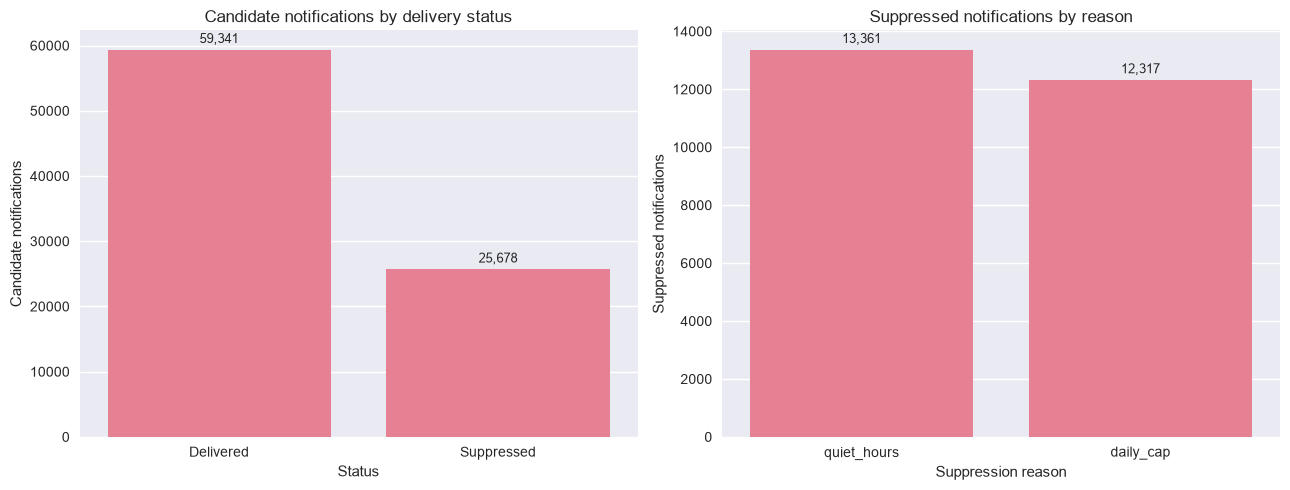

In [9]:
def label_bars(axis, percent=False, decimals=0):
    # Place readable values above vertical bars.
    for patch in axis.patches:
        value = patch.get_height()
        label = f"{value:.{decimals}f}%" if percent else f"{value:,.{decimals}f}"
        axis.annotate(
            label,
            (patch.get_x() + patch.get_width() / 2, value),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 3),
            textcoords="offset points",
        )

status_counts = analysis["delivered"].map({True: "Delivered", False: "Suppressed"}).value_counts()
reason_counts = analysis.loc[~analysis["delivered"], "suppression_reason"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=status_counts.index, y=status_counts.values, ax=axes[0])
sns.barplot(x=reason_counts.index, y=reason_counts.values, ax=axes[1])
axes[0].set(title="Candidate notifications by delivery status", xlabel="Status", ylabel="Candidate notifications")
axes[1].set(title="Suppressed notifications by reason", xlabel="Suppression reason", ylabel="Suppressed notifications")
label_bars(axes[0])
label_bars(axes[1])
plt.tight_layout()
plt.show()

The current synthetic policy already suppresses candidates for quiet hours and a daily cap, so the policy baseline is not equivalent to sending every candidate.

### Frequency and response

Use delivered events and the labeled prior-week count to compare click and engagement rates with explicit denominators.

,notifications_prior_7d,delivered_events,click_rate,engagement_rate
0,0,21949,0.325710,0.363433
1,1,26157,0.322591,0.362542
2,2,10154,0.317609,0.355919
3,3,1081,0.328400,0.375578


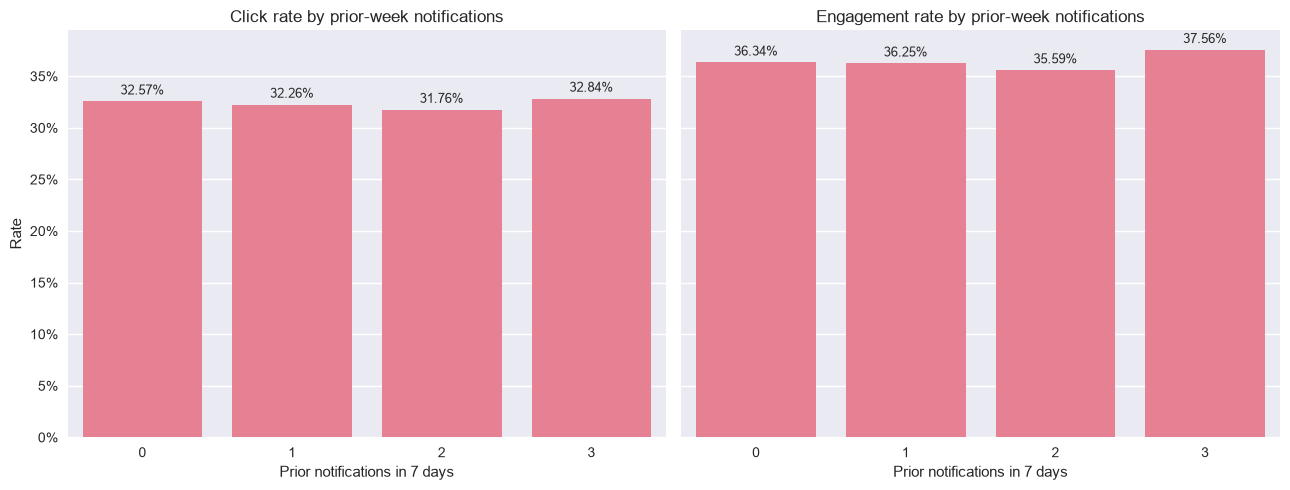

In [10]:
frequency_rates = delivered.groupby("notifications_prior_7d").agg(
    delivered_events=("user_id", "size"),
    click_rate=("clicked_24h", "mean"),
    engagement_rate=("engaged_24h", "mean"),
).reset_index()

display(frequency_rates)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for axis, metric, title in [
    (axes[0], "click_rate", "Click rate by prior-week notifications"),
    (axes[1], "engagement_rate", "Engagement rate by prior-week notifications"),
]:
    sns.barplot(data=frequency_rates, x="notifications_prior_7d", y=metric, ax=axis)
    axis.set(title=title, xlabel="Prior notifications in 7 days", ylabel="Rate")
    axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    for patch in axis.patches:
        value = patch.get_height()
        axis.annotate(f"{value:.2%}", (patch.get_x() + patch.get_width()/2, value),
                      ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

The displayed rates are descriptive associations; frequency may reflect user activity and selection as well as fatigue.

### Fatigue, response, and opt-outs

Create equal-count fatigue bands from delivered events and compare engagement efficiency with the opt-out guardrail.

,fatigue_quartile,delivered_events,click_rate,engagement_rate,opt_outs_per_1000
0,Lowest,14836,0.330413,0.368496,1.348072
1,Low,14835,0.322683,0.362791,1.550388
2,High,14835,0.323559,0.362319,2.494102
3,Highest,14835,0.315335,0.354297,2.089653


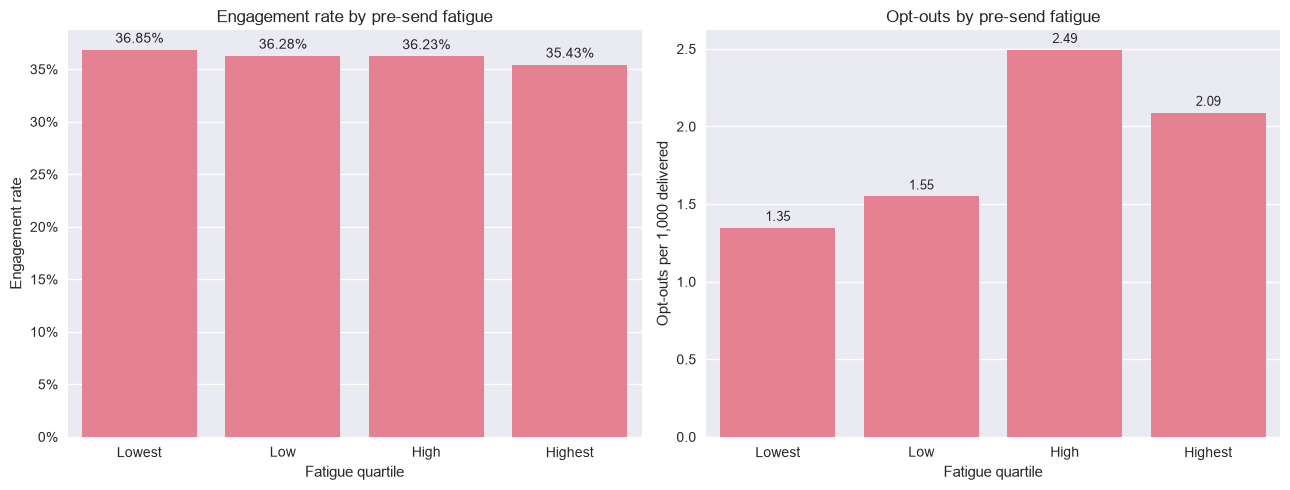

In [11]:
delivered["fatigue_quartile"] = pd.qcut(
    delivered["fatigue_before_send"],
    q=4,
    labels=["Lowest", "Low", "High", "Highest"],
)
fatigue_rates = delivered.groupby("fatigue_quartile", observed=True).agg(
    delivered_events=("user_id", "size"),
    click_rate=("clicked_24h", "mean"),
    engagement_rate=("engaged_24h", "mean"),
    opt_outs_per_1000=("unsubscribed_at_event", lambda values: values.mean() * 1000),
).reset_index()
display(fatigue_rates)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=fatigue_rates, x="fatigue_quartile", y="engagement_rate", ax=axes[0])
sns.barplot(data=fatigue_rates, x="fatigue_quartile", y="opt_outs_per_1000", ax=axes[1])
axes[0].set(title="Engagement rate by pre-send fatigue", xlabel="Fatigue quartile", ylabel="Engagement rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
axes[1].set(title="Opt-outs by pre-send fatigue", xlabel="Fatigue quartile", ylabel="Opt-outs per 1,000 delivered")
for patch in axes[0].patches:
    value = patch.get_height()
    axes[0].annotate(f"{value:.2%}", (patch.get_x()+patch.get_width()/2, value), ha="center", va="bottom", xytext=(0,3), textcoords="offset points")
label_bars(axes[1], decimals=2)
plt.tight_layout()
plt.show()

Higher pre-send fatigue bands show how response and opt-out risk move together in the simulation; this pattern does not identify the effect of changing fatigue.

### Segment differences

Compare volume and response by the baseline user segment.

,user_segment,delivered_events,notifications_per_user,click_rate,engagement_rate
2,power,8912,16.783427,0.350090,0.388353
3,regular,24073,14.053123,0.335895,0.372866
0,casual,20370,10.806366,0.304222,0.345214
1,low_activity,5986,6.928241,0.294688,0.335951


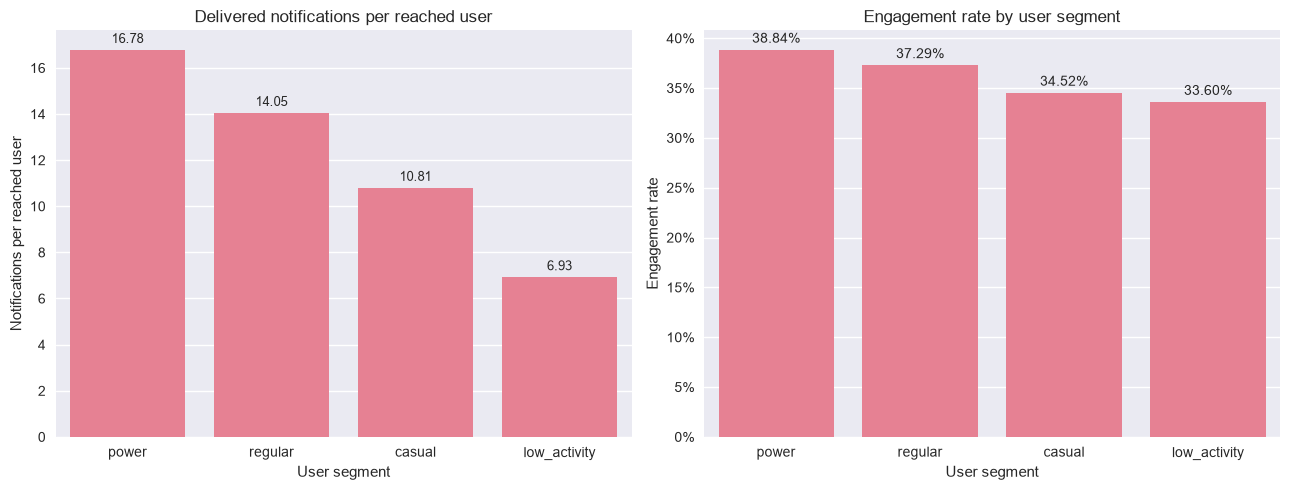

In [12]:
segment_rates = delivered.groupby("user_segment").agg(
    delivered_events=("user_id", "size"),
    notifications_per_user=("user_id", lambda values: len(values) / values.nunique()),
    click_rate=("clicked_24h", "mean"),
    engagement_rate=("engaged_24h", "mean"),
).reset_index().sort_values("engagement_rate", ascending=False)
display(segment_rates)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=segment_rates, x="user_segment", y="notifications_per_user", ax=axes[0])
sns.barplot(data=segment_rates, x="user_segment", y="engagement_rate", ax=axes[1])
axes[0].set(title="Delivered notifications per reached user", xlabel="User segment", ylabel="Notifications per reached user")
axes[1].set(title="Engagement rate by user segment", xlabel="User segment", ylabel="Engagement rate")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
label_bars(axes[0], decimals=2)
for patch in axes[1].patches:
    value = patch.get_height()
    axes[1].annotate(f"{value:.2%}", (patch.get_x()+patch.get_width()/2, value), ha="center", va="bottom", xytext=(0,3), textcoords="offset points")
plt.tight_layout()
plt.show()

Segment differences are useful for policy monitoring, but they combine baseline propensity, content mix, and exposure patterns.

### Sessions and retention availability

Check the raw schema before attempting the requested session and retention analysis.

In [13]:
requested_fields = ["session_count_7d", "session_count_30d", "retained_30d", "churn_target"]
for column in requested_fields:
    status = "available" if column in analysis.columns else "not available"
    print(f"{column}: {status}")

print(f"Observed classes in non-missing churn_target: {analysis['churn_target'].dropna().nunique():,}")

print("Churn-model eligible rows:", analysis["churn_model_eligible"].sum())

session_count_7d: not available
session_count_30d: not available
retained_30d: not available
churn_target: available
Observed classes in non-missing churn_target: 1
Churn-model eligible rows: 0


The raw schema cannot support session analysis. F01 now supplies evidence-backed negative churn labels and missing unverified outcomes. These selected negatives cannot support comparative retention or population churn rates; no proxy is substituted.

## Problem Statement

Quantify whether users with more recent notifications or higher pre-send fatigue also show different engagement rates, while keeping the analysis at user level for inference.

## Question 1: Is prior-week notification frequency associated with user engagement?

**Objective:** Measure the monotonic association between each user's mean labeled prior-week exposure and delivered-event engagement rate.

**H0:** The population Spearman association is zero.  
**H1:** The population Spearman association is not zero.

The test assumes independent user-level observations and a monotonic relationship for interpretation. A user bootstrap supplies the confidence interval.

In [14]:
def bootstrap_spearman(frame, x, y, repeats=1000, seed=42):
    # Bootstrap a user-level Spearman correlation.
    rng = np.random.default_rng(seed)
    values = np.empty(repeats)
    for index in range(repeats):
        sample = frame.iloc[rng.integers(0, len(frame), len(frame))]
        values[index] = stats.spearmanr(sample[x], sample[y]).statistic
    return np.percentile(values, [2.5, 97.5])

frequency_rho, frequency_p = stats.spearmanr(
    user_summary["mean_notifications_7d"],
    user_summary["engagement_rate"],
)
frequency_ci = bootstrap_spearman(
    user_summary,
    "mean_notifications_7d",
    "engagement_rate",
    seed=random_state,
)

print(f"Spearman effect size: {frequency_rho:.4f}")
print(f"95% confidence interval: [{frequency_ci[0]:.4f}, {frequency_ci[1]:.4f}]")
print(f"p-value: {frequency_p:.6g}")
if frequency_p < alpha:
    print("Reject H0: prior-week frequency is associated with user engagement in the synthetic data.")
else:
    print("Fail to reject H0: the synthetic data do not show a detectable association.")

Spearman effect size: 0.0667
95% confidence interval: [0.0381, 0.0957]
p-value: 2.37064e-06
Reject H0: prior-week frequency is associated with user engagement in the synthetic data.


The effect size and interval quantify association, not the causal impact of sending another notification.

## Question 2: Is pre-send fatigue associated with user engagement?

**Objective:** Measure the monotonic association between each user's mean pre-send fatigue and delivered-event engagement rate.

**H0:** The population Spearman association is zero.  
**H1:** The population Spearman association is not zero.

The test uses one row per reached user. The fatigue construction remains an open assumption documented in the decisions log.

In [15]:
fatigue_rho, fatigue_p = stats.spearmanr(
    user_summary["mean_fatigue"],
    user_summary["engagement_rate"],
)
fatigue_ci = bootstrap_spearman(
    user_summary,
    "mean_fatigue",
    "engagement_rate",
    seed=random_state,
)

print(f"Spearman effect size: {fatigue_rho:.4f}")
print(f"95% confidence interval: [{fatigue_ci[0]:.4f}, {fatigue_ci[1]:.4f}]")
print(f"p-value: {fatigue_p:.6g}")
if fatigue_p < alpha:
    print("Reject H0: pre-send fatigue is associated with user engagement in the synthetic data.")
else:
    print("Fail to reject H0: the synthetic data do not show a detectable association.")

Spearman effect size: -0.1410
95% confidence interval: [-0.1681, -0.1136]
p-value: 1.40352e-23
Reject H0: pre-send fatigue is associated with user engagement in the synthetic data.


The user-level result supports fatigue-aware monitoring but does not prove that changing the score changes engagement.

## Summary

Print the central descriptive and inferential outputs used in the product interpretation.

In [16]:
print(f"Delivered-event click rate: {delivered['clicked_24h'].mean():.2%}")
print(f"Delivered-event engagement rate: {delivered['engaged_24h'].mean():.2%}")
print(f"Delivered-event opt-out rate: {delivered['unsubscribed_at_event'].mean():.3%}")
print(f"Frequency association: rho={frequency_rho:.4f}, p={frequency_p:.6g}")
print(f"Fatigue association: rho={fatigue_rho:.4f}, p={fatigue_p:.6g}")

Delivered-event click rate: 32.30%
Delivered-event engagement rate: 36.20%
Delivered-event opt-out rate: 0.187%
Frequency association: rho=0.0667, p=2.37064e-06
Fatigue association: rho=-0.1410, p=1.40352e-23


The analysis provides auditable delivery, response, fatigue, and segment baselines. Session and retention conclusions remain unavailable from the raw schema.

## Insights

- Optimize meaningful engagement per notification, not raw delivery volume or CTR alone.
- Monitor fatigue and opt-outs alongside engagement because response efficiency and user burden can move differently.
- Segment-aware reporting is warranted, but policy thresholds should be validated prospectively rather than inferred causally from these associations.
- The findings come from synthetic data and cannot establish real-world causal impact.